## 2. K-means pe cele patru seturi reduse

### 2.1 Metoda cotului și scorul silhouette

Pentru fiecare set redus (98%, 95%, 90% și 80% din varianță) antrenez k-means pentru k de la 2 la 10 și salvez inertia și scorul silhouette.

- **Inertia** este suma distanțelor (la pătrat) de la fiecare casă la centrul clusterului ei. Scade mereu când crește k, așa că caut „cotul”, punctul după care adăugarea unui cluster nou mai aduce doar o îmbunătățire mică.
- **Scorul silhouette** (între −1 și 1) arată cât de bine separate sunt clusterele: valorile apropiate de 1 înseamnă grupuri clare, separate, iar cele apropiate de 0 înseamnă clustere care se suprapun.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from lab3_utils import get_all_variants

SEED = 42
V = get_all_variants(path="../data/AmesHousing.csv")
y = V["minmax"]["y"]  # clasele de preț, folosite doar pentru comparație, nu la clustering
thresholds = [0.98, 0.95, 0.90, 0.80]
ks = range(2, 11)

rows = []
for variant, data in V.items():
    for t in thresholds:
        Z = data["Z"][t]
        for k in ks:
            km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
            rows.append({"variant": variant, "threshold": t, "components": Z.shape[1], "k": k,
                         "inertia": km.inertia_,
                         "silhouette": silhouette_score(Z, km.labels_),
                         "ari_price": adjusted_rand_score(y, km.labels_)})
grid = pd.DataFrame(rows)
grid.to_csv("kmeans_grid.csv", index=False)   # salvat, ca să nu se piardă nimic după un restart
print(grid.shape)
grid.head()

(144, 7)


,variant,threshold,components,k,inertia,silhouette,ari_price
0,minmax,0.98,123,2,26689.981010,0.103151,0.148822
1,minmax,0.98,123,3,24896.724692,0.102748,0.155728
2,minmax,0.98,123,4,23729.748220,0.090422,0.142372
3,minmax,0.98,123,5,23010.187504,0.092892,0.111326
4,minmax,0.98,123,6,22483.150561,0.097358,0.111840


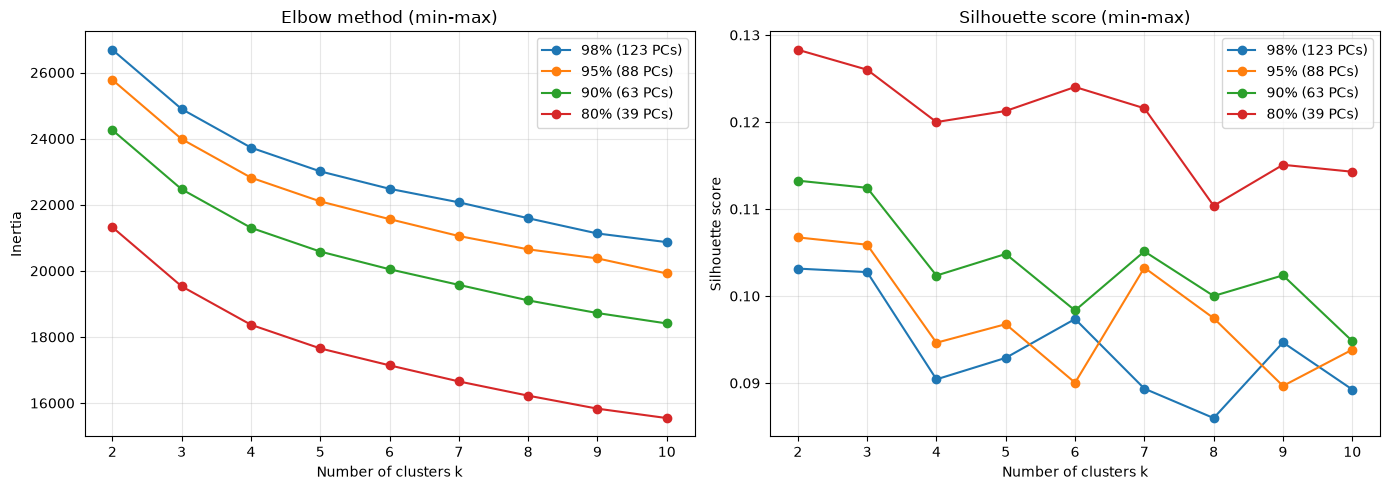

,threshold,components,k,silhouette
27,0.80,39,2,0.128
18,0.90,63,2,0.113
9,0.95,88,2,0.107
0,0.98,123,2,0.103


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mm = grid[grid["variant"] == "minmax"]
for t in thresholds:
    r = mm[mm["threshold"] == t]
    label = f"{int(t*100)}% ({r['components'].iloc[0]} PCs)"
    axes[0].plot(r["k"], r["inertia"], "o-", label=label)
    axes[1].plot(r["k"], r["silhouette"], "o-", label=label)
axes[0].set(xlabel="Number of clusters k", ylabel="Inertia", title="Elbow method (min-max)")
axes[1].set(xlabel="Number of clusters k", ylabel="Silhouette score", title="Silhouette score (min-max)")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# Cel mai bun k pentru fiecare prag, după scorul silhouette
display(mm.loc[mm.groupby("threshold")["silhouette"].idxmax(), ["threshold", "components", "k", "silhouette"]].round(3))

**Interpretare**

Inertia scade lin pentru toate cele patru seturi și nu există un cot clar. Cea mai vizibilă îndoire este în jurul lui k = 3–4: până acolo, un cluster în plus reduce vizibil inertia, după aceea câștigul devine mai mic. Curbele cu mai puține componente sunt mai jos doar pentru că în date rămâne mai puțină varianță, deci inertia nu se poate compara între praguri.

Scorul silhouette este maxim la k = 2 pentru toate pragurile, dar k = 3 este aproape la fel (de exemplu 0.103 vs. 0.103 la 98%). Toate valorile sunt foarte mici (0.09–0.13), ceea ce înseamnă că casele nu formează grupuri bine separate. Cu mai puține componente scorul silhouette e puțin mai mare (0.128 la 80% vs. 0.103 la 98%), probabil pentru că ultimele componente adaugă mai ales zgomot la distanțe.

Pe baza cotului și a scorului silhouette, k = 2 și k = 3 sunt cei mai buni candidați. Cotul îl calculez mai jos.

In [3]:
# Cotul = punctul de pe curbă cel mai depărtat de dreapta care unește primul și ultimul punct
def gaseste_cotul(ks, inertia):
    ks, inertia = np.array(ks), np.array(inertia)
    x = (ks - ks[0]) / (ks[-1] - ks[0])
    yv = (inertia - inertia[-1]) / (inertia[0] - inertia[-1])
    return int(ks[np.argmax((1 - x) - yv)])

print("Cotul pentru fiecare prag:",
      {f"{int(t*100)}%": gaseste_cotul(mm[mm["threshold"] == t]["k"].values, mm[mm["threshold"] == t]["inertia"].values)
       for t in thresholds})

# Cu cât scade inertia (în %) la fiecare cluster adăugat
display(mm.pivot(index="k", columns="threshold", values="inertia").pct_change().mul(-100).round(1))

Cotul pentru fiecare prag: {'98%': 4, '95%': 4, '90%': 4, '80%': 4}


threshold,0.80,0.90,0.95,0.98
k,,,,
2,NaN,NaN,NaN,NaN
3,8.4,7.4,7.0,6.7
4,6.0,5.2,4.9,4.7
5,3.9,3.4,3.2,3.0
6,2.9,2.6,2.4,2.3
7,2.8,2.4,2.4,1.8
8,2.6,2.4,1.9,2.2
9,2.4,2.0,1.3,2.1
10,1.8,1.7,2.2,1.2


Calculat, cotul este la k = 4 pentru toate pragurile. Până la k = 4, fiecare cluster în plus reduce inertia cu 5–8%, după aceea doar cu 2–3%. Metoda cotului (cât de compacte sunt clusterele) indică deci k = 4, iar scorul silhouette (cât de separate sunt) indică k = 2. Alegem k = 2 pentru că este susținut de mai multe măsuri (silhouette, Calinski-Harabasz, stabilitate), dar k = 4 rămâne o alternativă rezonabilă.

In [4]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

Z = V["minmax"]["Z"][0.98]
rows = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
    rows.append({"k": k, "silhouette (mare = bine)": silhouette_score(Z, labels),
                 "Calinski-Harabasz (mare = bine)": calinski_harabasz_score(Z, labels),
                 "Davies-Bouldin (mic = bine)": davies_bouldin_score(Z, labels)})
display(pd.DataFrame(rows).set_index("k").round(3))

,silhouette (mare = bine),Calinski-Harabasz (mare = bine),Davies-Bouldin (mic = bine)
k,,,
2,0.103,356.286,2.721
3,0.103,296.322,2.833
4,0.090,255.157,2.706
5,0.093,220.152,2.926
6,0.097,193.897,2.911
7,0.089,173.563,3.077
8,0.086,161.326,2.987
9,0.095,152.179,2.887
10,0.089,140.990,2.819


Ca alegerea lui k să nu depindă de o singură măsură, am calculat încă doi indici. Calinski-Harabasz este maxim la k = 2 (356) și scade continuu. Davies-Bouldin este aproape egal la k = 4 (2.71) și k = 2 (2.72). Două din trei măsuri indică k = 2.

### 2.2 Silhouette plots

Scorul silhouette este doar o medie. Un silhouette plot arată valoarea silhouette a fiecărei case, grupată pe clustere și sortată. Clusterele late, cu valori peste linia mediei, sunt bune. Clusterele subțiri sau multe valori negative (case mai apropiate de alt cluster decât de al lor) arată o împărțire proastă. Le desenez pentru k = 2…5, pentru fiecare dintre cele patru praguri.

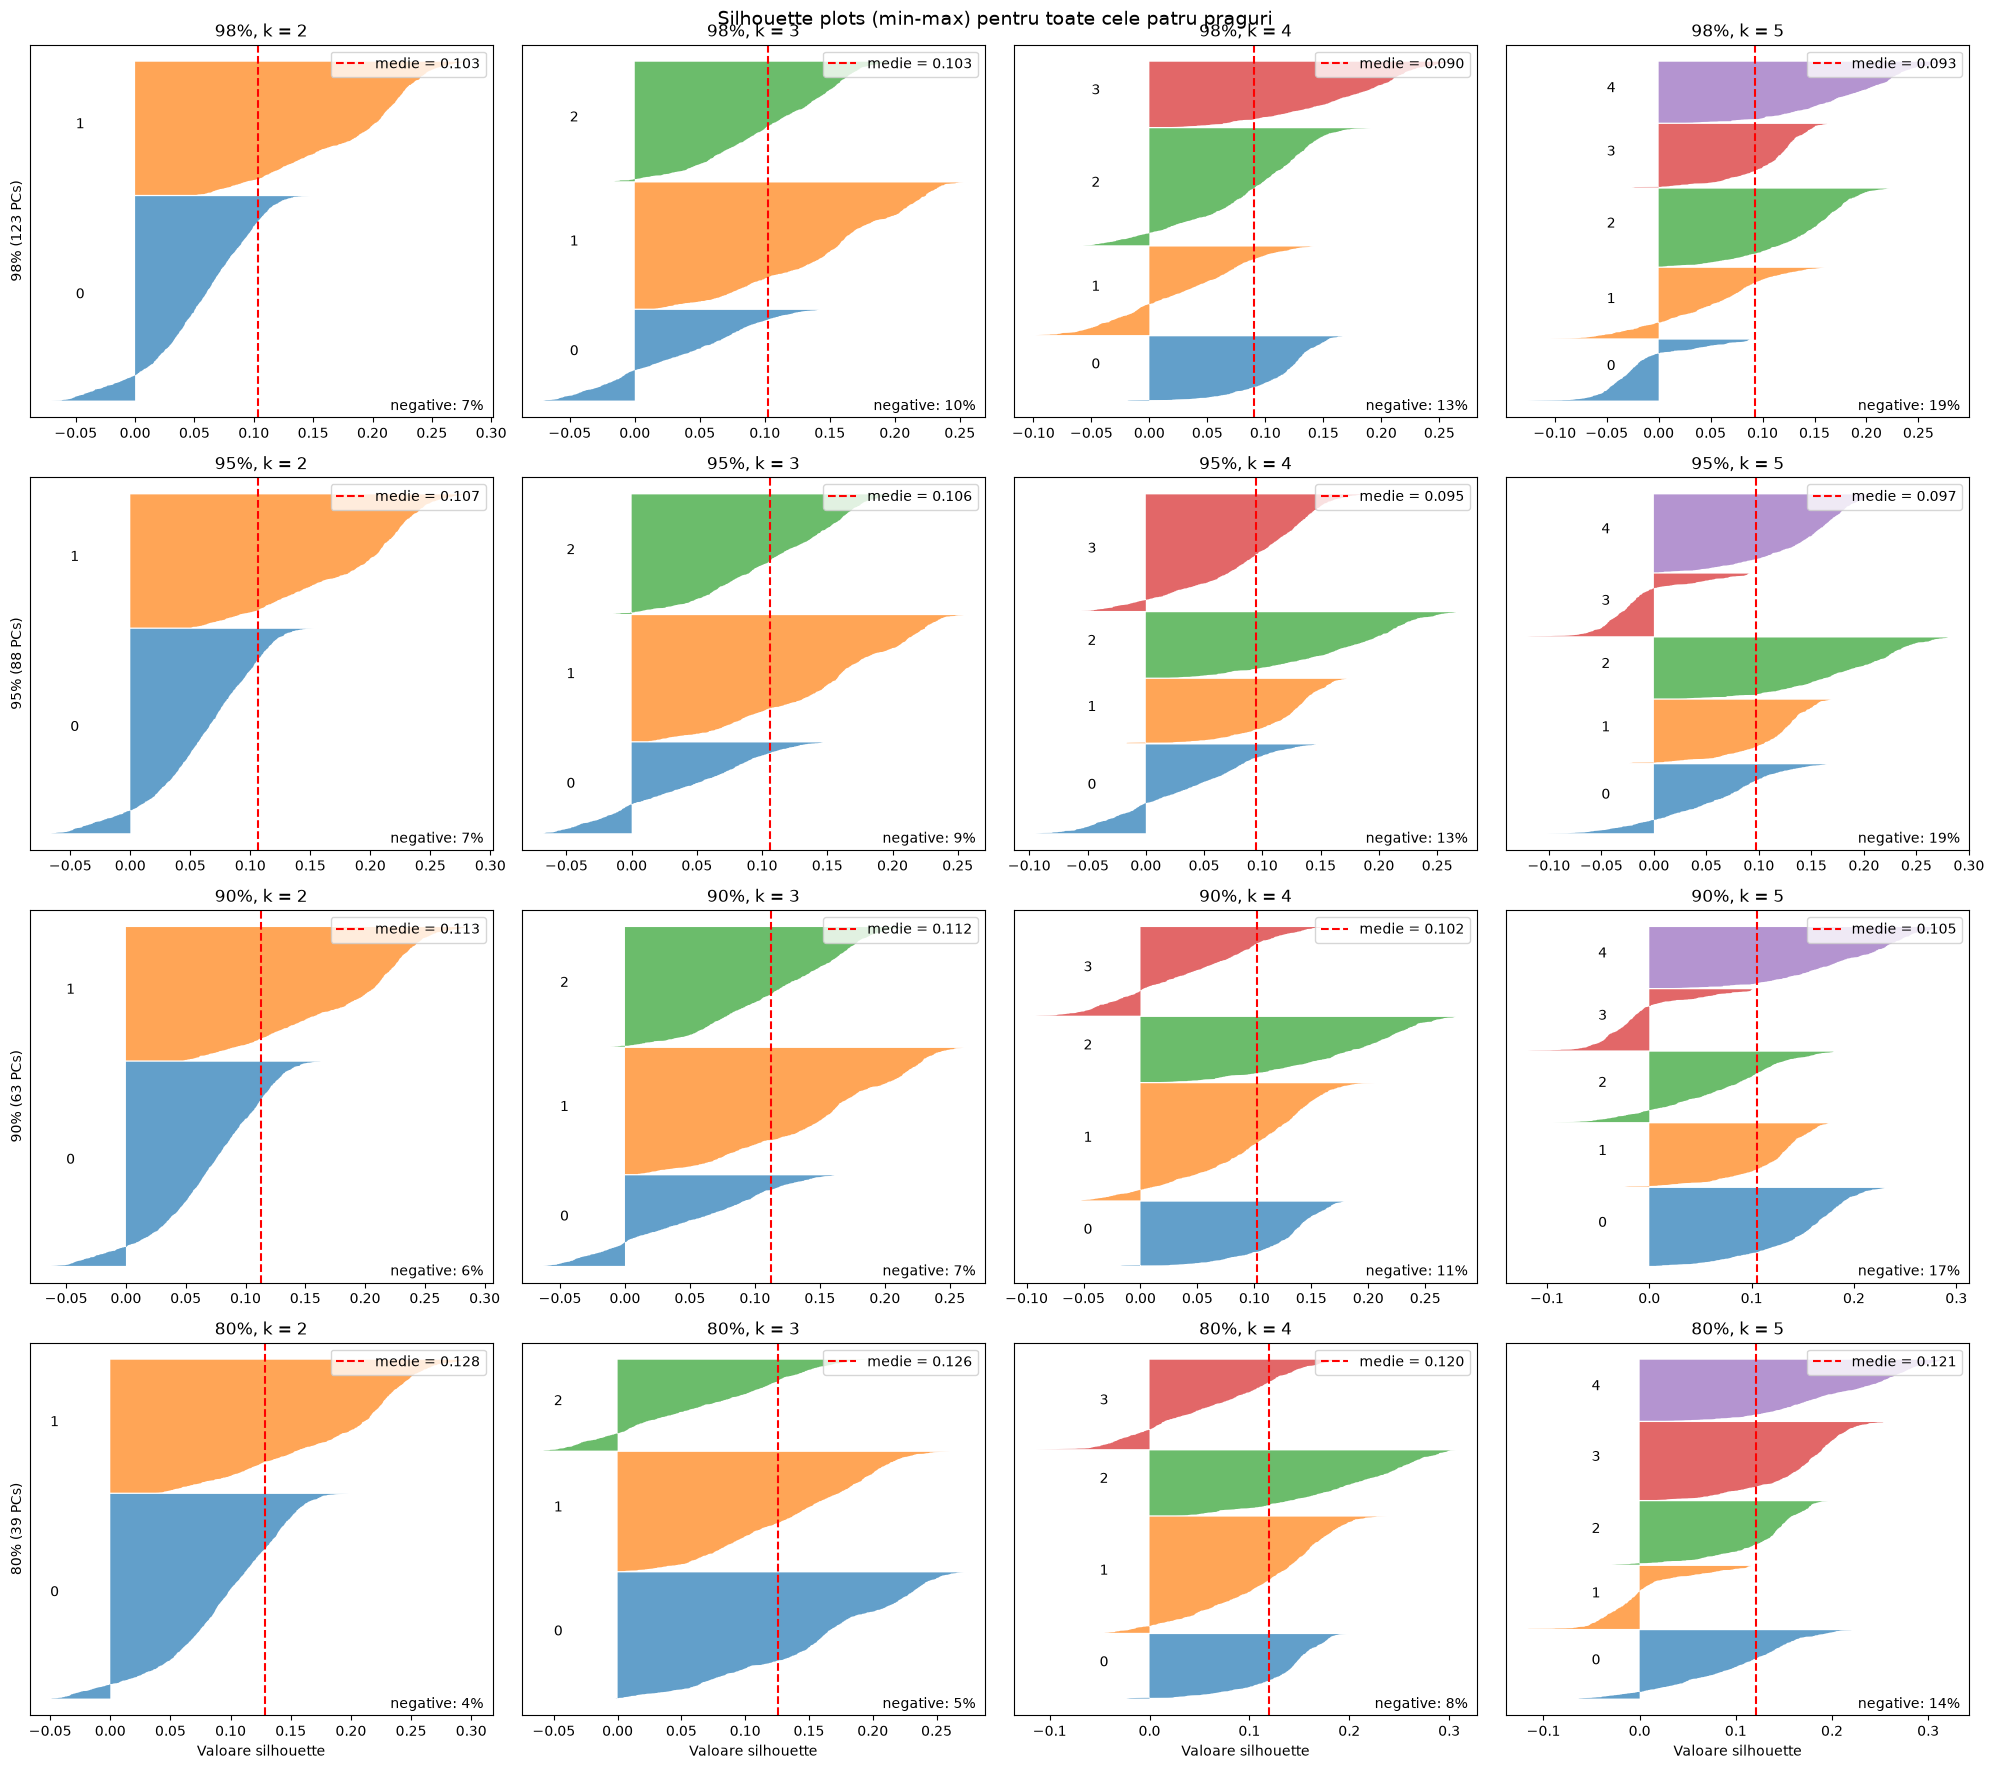

In [5]:
from sklearn.metrics import silhouette_samples

fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for row, t in enumerate(thresholds):
    Z = V["minmax"]["Z"][t]
    for col, k in enumerate([2, 3, 4, 5]):
        ax = axes[row, col]
        labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
        s = silhouette_samples(Z, labels)
        y_low = 10
        for c in range(k):
            vals = np.sort(s[labels == c])
            ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, alpha=0.7)
            ax.text(-0.05, y_low + len(vals) / 2, str(c))
            y_low += len(vals) + 10
        ax.axvline(s.mean(), color="red", linestyle="--", label=f"medie = {s.mean():.3f}")
        ax.set(title=f"{int(t*100)}%, k = {k}", yticks=[])
        ax.text(0.98, 0.02, f"negative: {(s < 0).mean():.0%}", transform=ax.transAxes, ha="right")
        ax.legend(loc="upper right")
    axes[row, 0].set_ylabel(f"{int(t*100)}% ({Z.shape[1]} PCs)")
for ax in axes[-1]:
    ax.set_xlabel("Valoare silhouette")
plt.suptitle("Silhouette plots (min-max) pentru toate cele patru praguri", fontsize=14)
plt.tight_layout(); plt.show()

**Interpretare**

La pragul de 98%, pentru k = 2 ambele clustere sunt late și aproape toate casele au valori silhouette pozitive; doar 7% sunt negative, adică sunt mai apropiate de celălalt cluster decât de al lor. Pentru k = 3 procentul de valori negative crește la 10%, iar cel mai mic cluster are o „coadă” lungă spre stânga. Pentru k = 4 și k = 5 apar clustere mici, cu multe valori negative (13% și 19%). Toate valorile silhouette rămân sub aproximativ 0.25, deci chiar și cele mai bune clustere se suprapun mult. k = 2 dă cea mai curată împărțire, iar k = 3 e încă acceptabil; cu mai multe clustere, tot mai multe case ajung în grupul greșit.

La toate pragurile imaginea este aceeași: procentul de case cu valori negative crește odată cu k (de exemplu la 80%: 4%, 5%, 8%, 14% pentru k = 2…5). Cu mai puține componente, procentul e puțin mai mic.

### 2.3 Min-max vs. standardizare, cu și fără logaritmare

Repet graficele cotului și silhouette pentru celelalte trei variante: standardizare, min-max cu logaritmarea features-urilor asimetrice și standardizare cu logaritmare. Rezultatele sunt citite din același tabel `grid`, deci toate variantele folosesc aceleași setări k-means și același seed.

18 coloane logaritmate: ['Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Total Bsmt SF', '1st Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Half Bath', 'Kitchen AbvGr', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val']


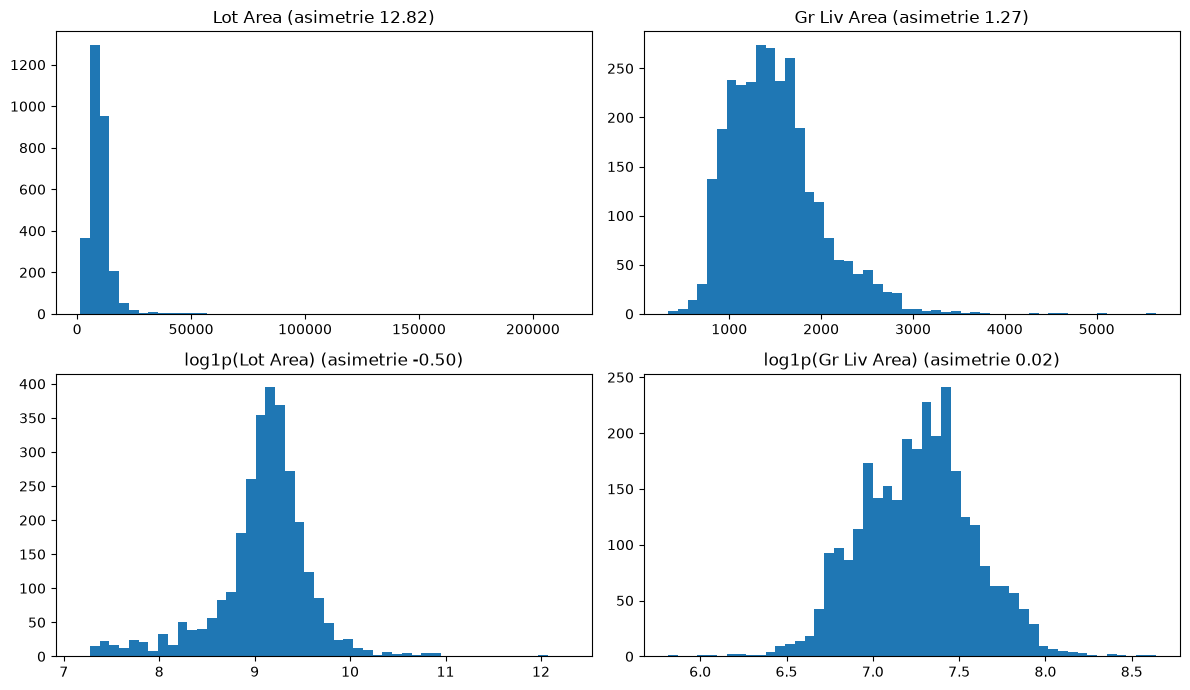

In [6]:
coloane_log = V["minmax_log"]["log_columns"]
print(len(coloane_log), "coloane logaritmate:", coloane_log)

X = V["minmax"]["X"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, nume in enumerate(["Lot Area", "Gr Liv Area"]):
    axes[0, col].hist(X[nume], bins=50)
    axes[0, col].set_title(f"{nume} (asimetrie {X[nume].skew():.2f})")
    axes[1, col].hist(np.log1p(X[nume]), bins=50)
    axes[1, col].set_title(f"log1p({nume}) (asimetrie {np.log1p(X[nume]).skew():.2f})")
plt.tight_layout(); plt.show()

Sunt logaritmate 18 coloane numerice cu asimetrie mare (|skew| > 1), de exemplu suprafețele. La `Lot Area`, câteva terenuri uriașe împing restul caselor spre 0 după scalare; după logaritmare distribuția devine aproape simetrică (asimetria scade de la 12.8 la −0.5, iar la `Gr Liv Area` de la 1.3 la 0.0).

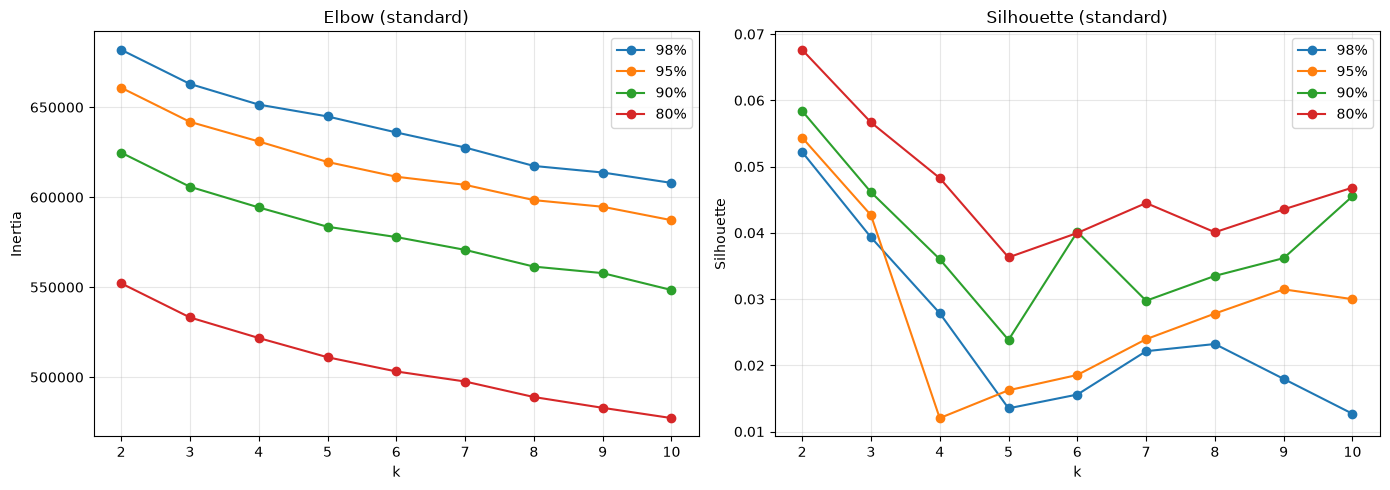

In [7]:
VARIANTA = "standard"      # <-- doar asta o schimb

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
date = grid[grid["variant"] == VARIANTA]
for t in thresholds:
    r = date[date["threshold"] == t]
    axes[0].plot(r["k"], r["inertia"], "o-", label=f"{int(t*100)}%")
    axes[1].plot(r["k"], r["silhouette"], "o-", label=f"{int(t*100)}%")
axes[0].set(xlabel="k", ylabel="Inertia", title=f"Elbow ({VARIANTA})")
axes[1].set(xlabel="k", ylabel="Silhouette", title=f"Silhouette ({VARIANTA})")
for ax in axes: ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Standardizare:** scorul silhouette este de aproximativ 2× mai mic decât la min-max (maxim 0.068 vs. 0.128), tot k = 2 e cel mai bun, iar curbele sunt instabile. Motivul: la standardizare toate coloanele au aceeași greutate, inclusiv coloanele one-hot rare, care adaugă zgomot.

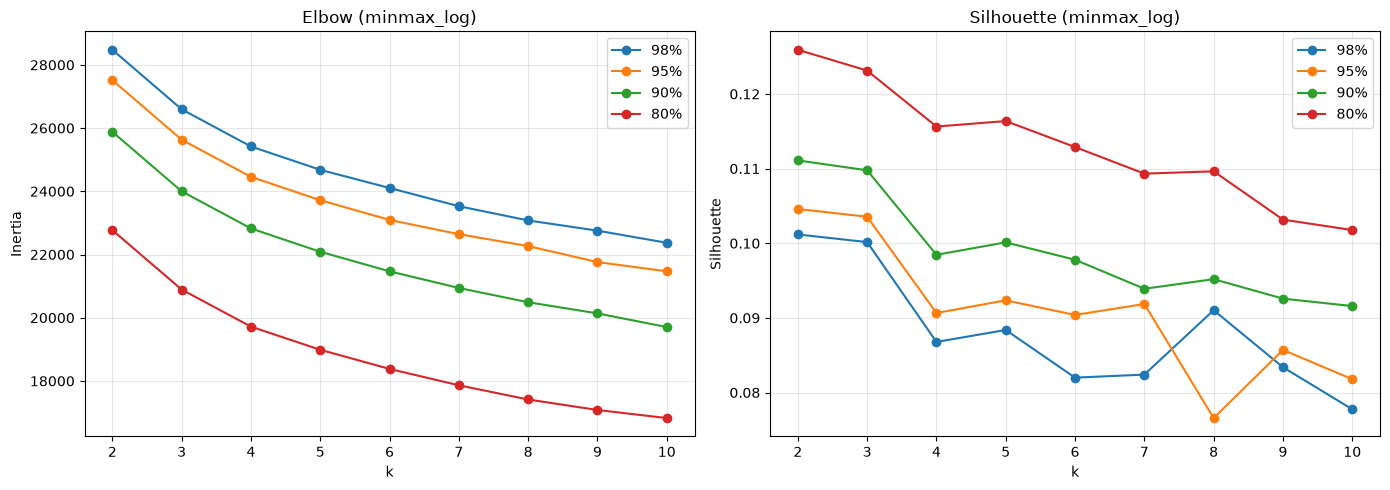

In [8]:
VARIANTA = "minmax_log"      # <-- doar asta o schimb

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
date = grid[grid["variant"] == VARIANTA]
for t in thresholds:
    r = date[date["threshold"] == t]
    axes[0].plot(r["k"], r["inertia"], "o-", label=f"{int(t*100)}%")
    axes[1].plot(r["k"], r["silhouette"], "o-", label=f"{int(t*100)}%")
axes[0].set(xlabel="k", ylabel="Inertia", title=f"Elbow ({VARIANTA})")
axes[1].set(xlabel="k", ylabel="Silhouette", title=f"Silhouette ({VARIANTA})")
for ax in axes: ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Min-max + logaritmare:** practic identic cu min-max (silhouette 0.101 vs. 0.103). Logaritmarea schimbă doar 18 coloane asimetrice, iar distanțele sunt dominate de coloanele one-hot. Distribuțiile devin mai simetrice, dar nu apar grupuri mai clare.

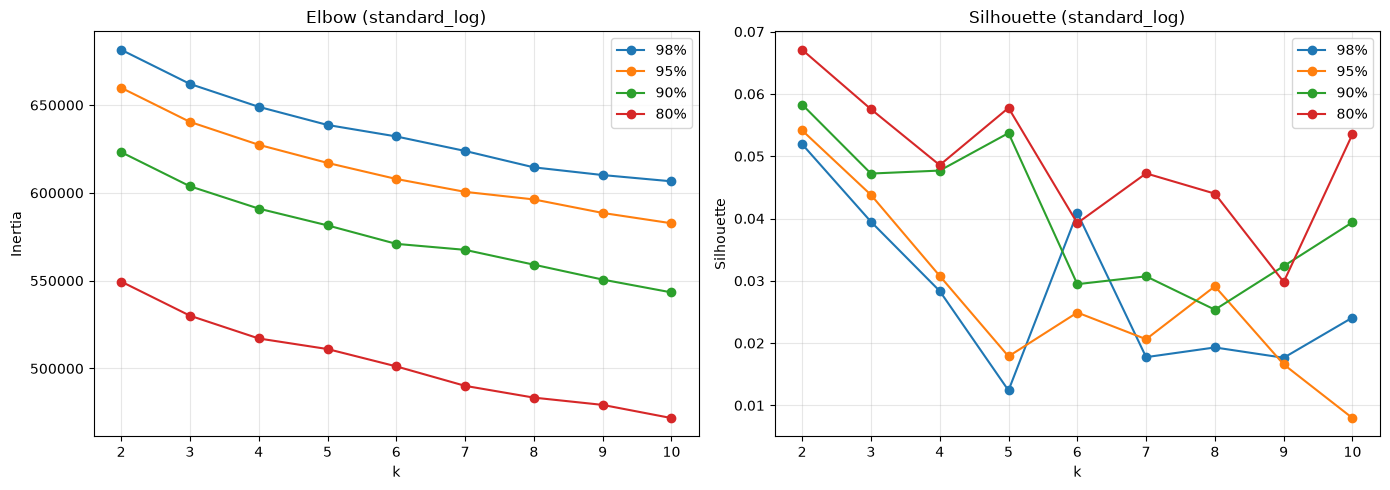

In [9]:
VARIANTA = "standard_log"      # <-- doar asta o schimb

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
date = grid[grid["variant"] == VARIANTA]
for t in thresholds:
    r = date[date["threshold"] == t]
    axes[0].plot(r["k"], r["inertia"], "o-", label=f"{int(t*100)}%")
    axes[1].plot(r["k"], r["silhouette"], "o-", label=f"{int(t*100)}%")
axes[0].set(xlabel="k", ylabel="Inertia", title=f"Elbow ({VARIANTA})")
axes[1].set(xlabel="k", ylabel="Silhouette", title=f"Silhouette ({VARIANTA})")
for ax in axes: ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Standardizare + logaritmare:** practic identic cu standardizarea (maxim 0.067 vs. 0.068), iar curbele sunt și mai haotice la k mare. Logaritmarea nu rezolvă problema standardizării: coloanele one-hot rare continuă să domine.

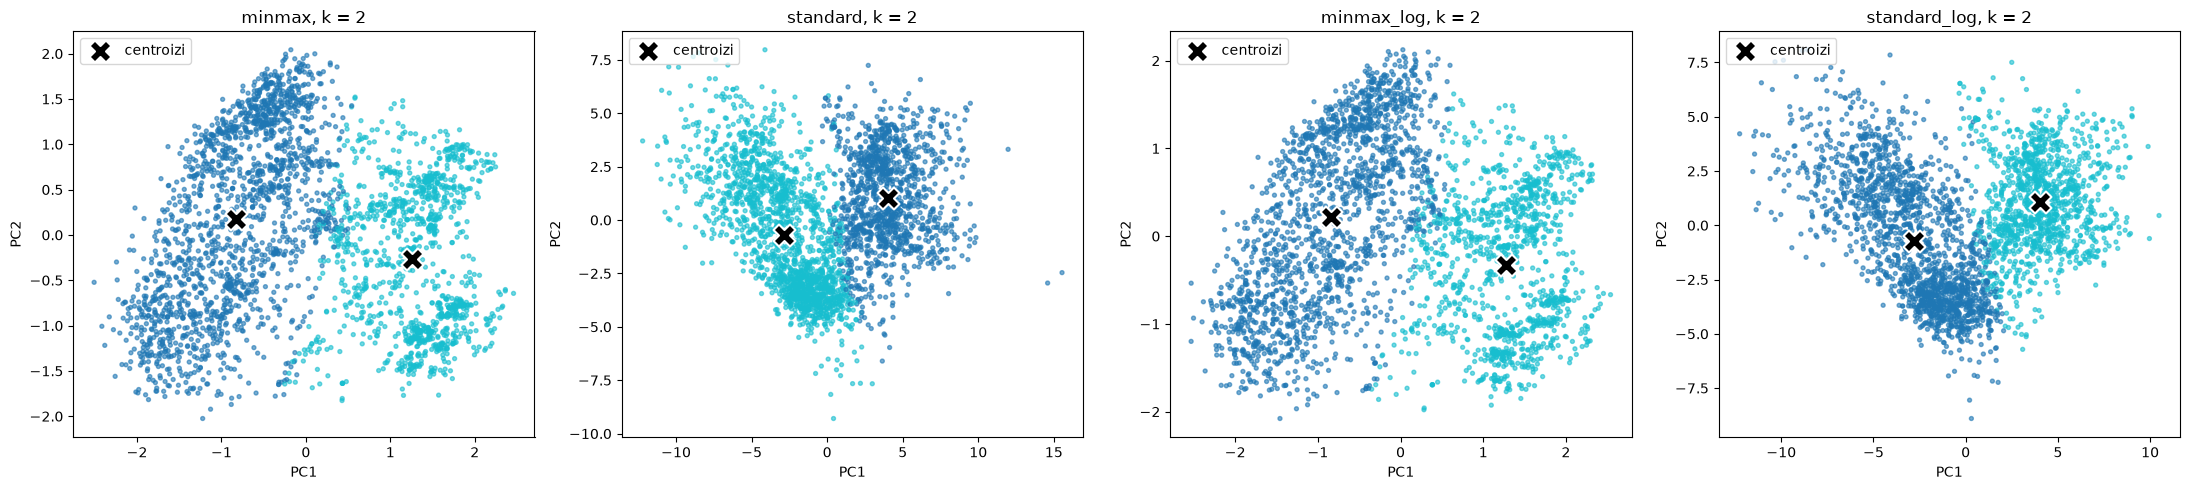

,minmax,standard,minmax_log,standard_log
minmax,1.000,0.803,0.969,0.812
standard,0.803,1.000,0.821,0.974
minmax_log,0.969,0.821,1.000,0.833
standard_log,0.812,0.974,0.833,1.000


In [10]:
variante = ["minmax", "standard", "minmax_log", "standard_log"]
etichete = {}
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, varianta in zip(axes, variante):
    Z = V[varianta]["Z"][0.98]
    km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(Z)
    etichete[varianta] = km.labels_
    ax.scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap="tab10", s=8, alpha=0.6)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c="black", marker="X", s=250,
               edgecolors="white", linewidths=1.5, label="centroizi")
    ax.set(title=f"{varianta}, k = 2", xlabel="PC1", ylabel="PC2")
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# Cât de asemănătoare sunt clusterele între variante (1 = identice)
ari_variante = pd.DataFrame([[adjusted_rand_score(etichete[a], etichete[b]) for b in variante] for a in variante],
                            index=variante, columns=variante)
display(ari_variante.round(3))

În toate variantele, k = 2 împarte casele de-a lungul lui PC1 (axele diferă, pentru că fiecare variantă are propriul PCA). Logaritmarea aproape nu schimbă clusterele (ARI 0.97 cu și fără log), în timp ce scalarea le schimbă mai mult (ARI 0.80 între min-max și standardizare).

**Comparație între cele patru variante**

| Variantă | Silhouette maxim (80%) | Silhouette maxim (98%) | Cel mai bun k |
|---|---|---|---|
| min-max | 0.128 | 0.103 | 2 (3 aproape la fel) |
| min-max + log | 0.126 | 0.101 | 2 (3 aproape la fel) |
| standardizare | 0.068 | 0.052 | 2 |
| standardizare + log | 0.067 | 0.052 | 2 |

**Scalarea contează mult.** Cu standardizare, scorul silhouette e cam la jumătate față de min-max, iar curbele sunt mult mai instabile. La standardizare fiecare feature primește varianța 1, deci coloanele one-hot rare (de exemplu un cartier cu câteva case) contează la fel de mult ca features-urile numerice importante. Ele împing casele în direcții întâmplătoare și grupurile se suprapun și mai mult. La min-max, o coloană 0/1 rară are varianță mică și influențează mai puțin distanțele.

**Logaritmarea aproape nu contează.** Ea schimbă doar coloanele numerice puternic asimetrice (18 din 250, de exemplu `Lot Area`, `Gr Liv Area`). Distribuția lor devine mai simetrică, valorile se întind mai uniform și inertia crește puțin, dar distanțele rămân dominate de multele coloane one-hot, deci nu apar grupuri mai clare.

În toate variantele k = 2 are cel mai bun scor silhouette, mai puține componente (80%) dau scoruri puțin mai bune, iar toate valorile rămân mici. Casele nu formează grupuri bine separate, oricum ar fi scalate datele.

**Normalizare L2 (pe rânduri)**

În sklearn, „normalizare” înseamnă scalarea fiecărei case (rând) la lungimea 1 (`Normalizer`), nu a fiecărei coloane. Ca să acoperim și acest sens, repet experimentul cu această variantă, pe datele nescalate.

In [11]:
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import PCA

X = V["minmax"]["X"]                                            # datele nescalate
X_l2 = pd.DataFrame(Normalizer().fit_transform(X), columns=X.columns)
print("Ponderea lui Lot Area în lungimea fiecărui rând (mediana):",
      round(((X["Lot Area"] ** 2) / (X ** 2).sum(axis=1)).median(), 3))

rows = []
for t in thresholds:
    pca_l2 = PCA(n_components=t, svd_solver="full", random_state=SEED).fit(X_l2)
    Z = pca_l2.transform(X_l2)
    for k in [2, 3, 4]:
        labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
        rows.append({"prag": t, "componente": Z.shape[1], "k": k,
                     "silhouette": silhouette_score(Z, labels), "ari_price": adjusted_rand_score(y, labels)})
display(pd.DataFrame(rows).round(3))

pca_l2 = PCA(n_components=0.98, svd_solver="full", random_state=SEED).fit(X_l2)
labels_l2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(pca_l2.transform(X_l2))
print("PC1 explică", round(pca_l2.explained_variance_ratio_[0] * 100, 1), "% din varianță")
display(X[["Lot Area", "Gr Liv Area", "Year Built"]].assign(cluster=labels_l2).groupby("cluster").median()
         .assign(case=np.bincount(labels_l2)))

Ponderea lui Lot Area în lungimea fiecărui rând (mediana): 0.799


,prag,componente,k,silhouette,ari_price
0,0.98,8,2,0.614,0.002
1,0.98,8,3,0.280,0.015
2,0.98,8,4,0.267,0.019
3,0.95,5,2,0.620,0.003
4,0.95,5,3,0.292,0.016
5,0.95,5,4,0.279,0.019
6,0.90,4,2,0.626,0.003
7,0.90,4,3,0.298,0.016
8,0.90,4,4,0.282,0.019
9,0.80,2,2,0.686,0.003


PC1 explică 74.5 % din varianță


,Lot Area,Gr Liv Area,Year Built,case
cluster,,,,
0,9788.0,1477.5,1971.0,2590
1,3616.5,1257.0,1985.0,340


Cu normalizarea L2, scorul silhouette pare foarte bun (0.61–0.69 la k = 2), dar clusterele nu au aproape nicio legătură cu prețul (ARI ≈ 0.003). Motivul: normalizarea pe rânduri nu aduce coloanele la aceeași scară, deci `Lot Area` (valori de ordinul 10 000) reprezintă în mediană 80% din lungimea fiecărui rând. PCA ajunge să aibă doar 2–8 componente, iar PC1 (74.5% din varianță) descrie aproape doar suprafața terenului. K-means separă astfel 340 de case cu teren mic (mediana 3 600 sqft) de restul. Un scor silhouette mare nu înseamnă clustere cu sens: aici grupurile sunt clare, dar sunt determinate de o singură coloană cu valori mari.

### 2.4 Clusterele în planul primelor două componente

Desenez casele în planul PC1–PC2, colorate după clusterul primit de la k-means, iar centroizii cu un simbol diferit (X). Fac asta pentru toate cele patru praguri (98%, 95%, 90%, 80%) și pentru k = 2, 3 și 4. K-means este antrenat pe toate componentele setului respectiv, dar graficul arată doar primele două, deci centroizii sunt și ei desenați doar cu primele două coordonate.

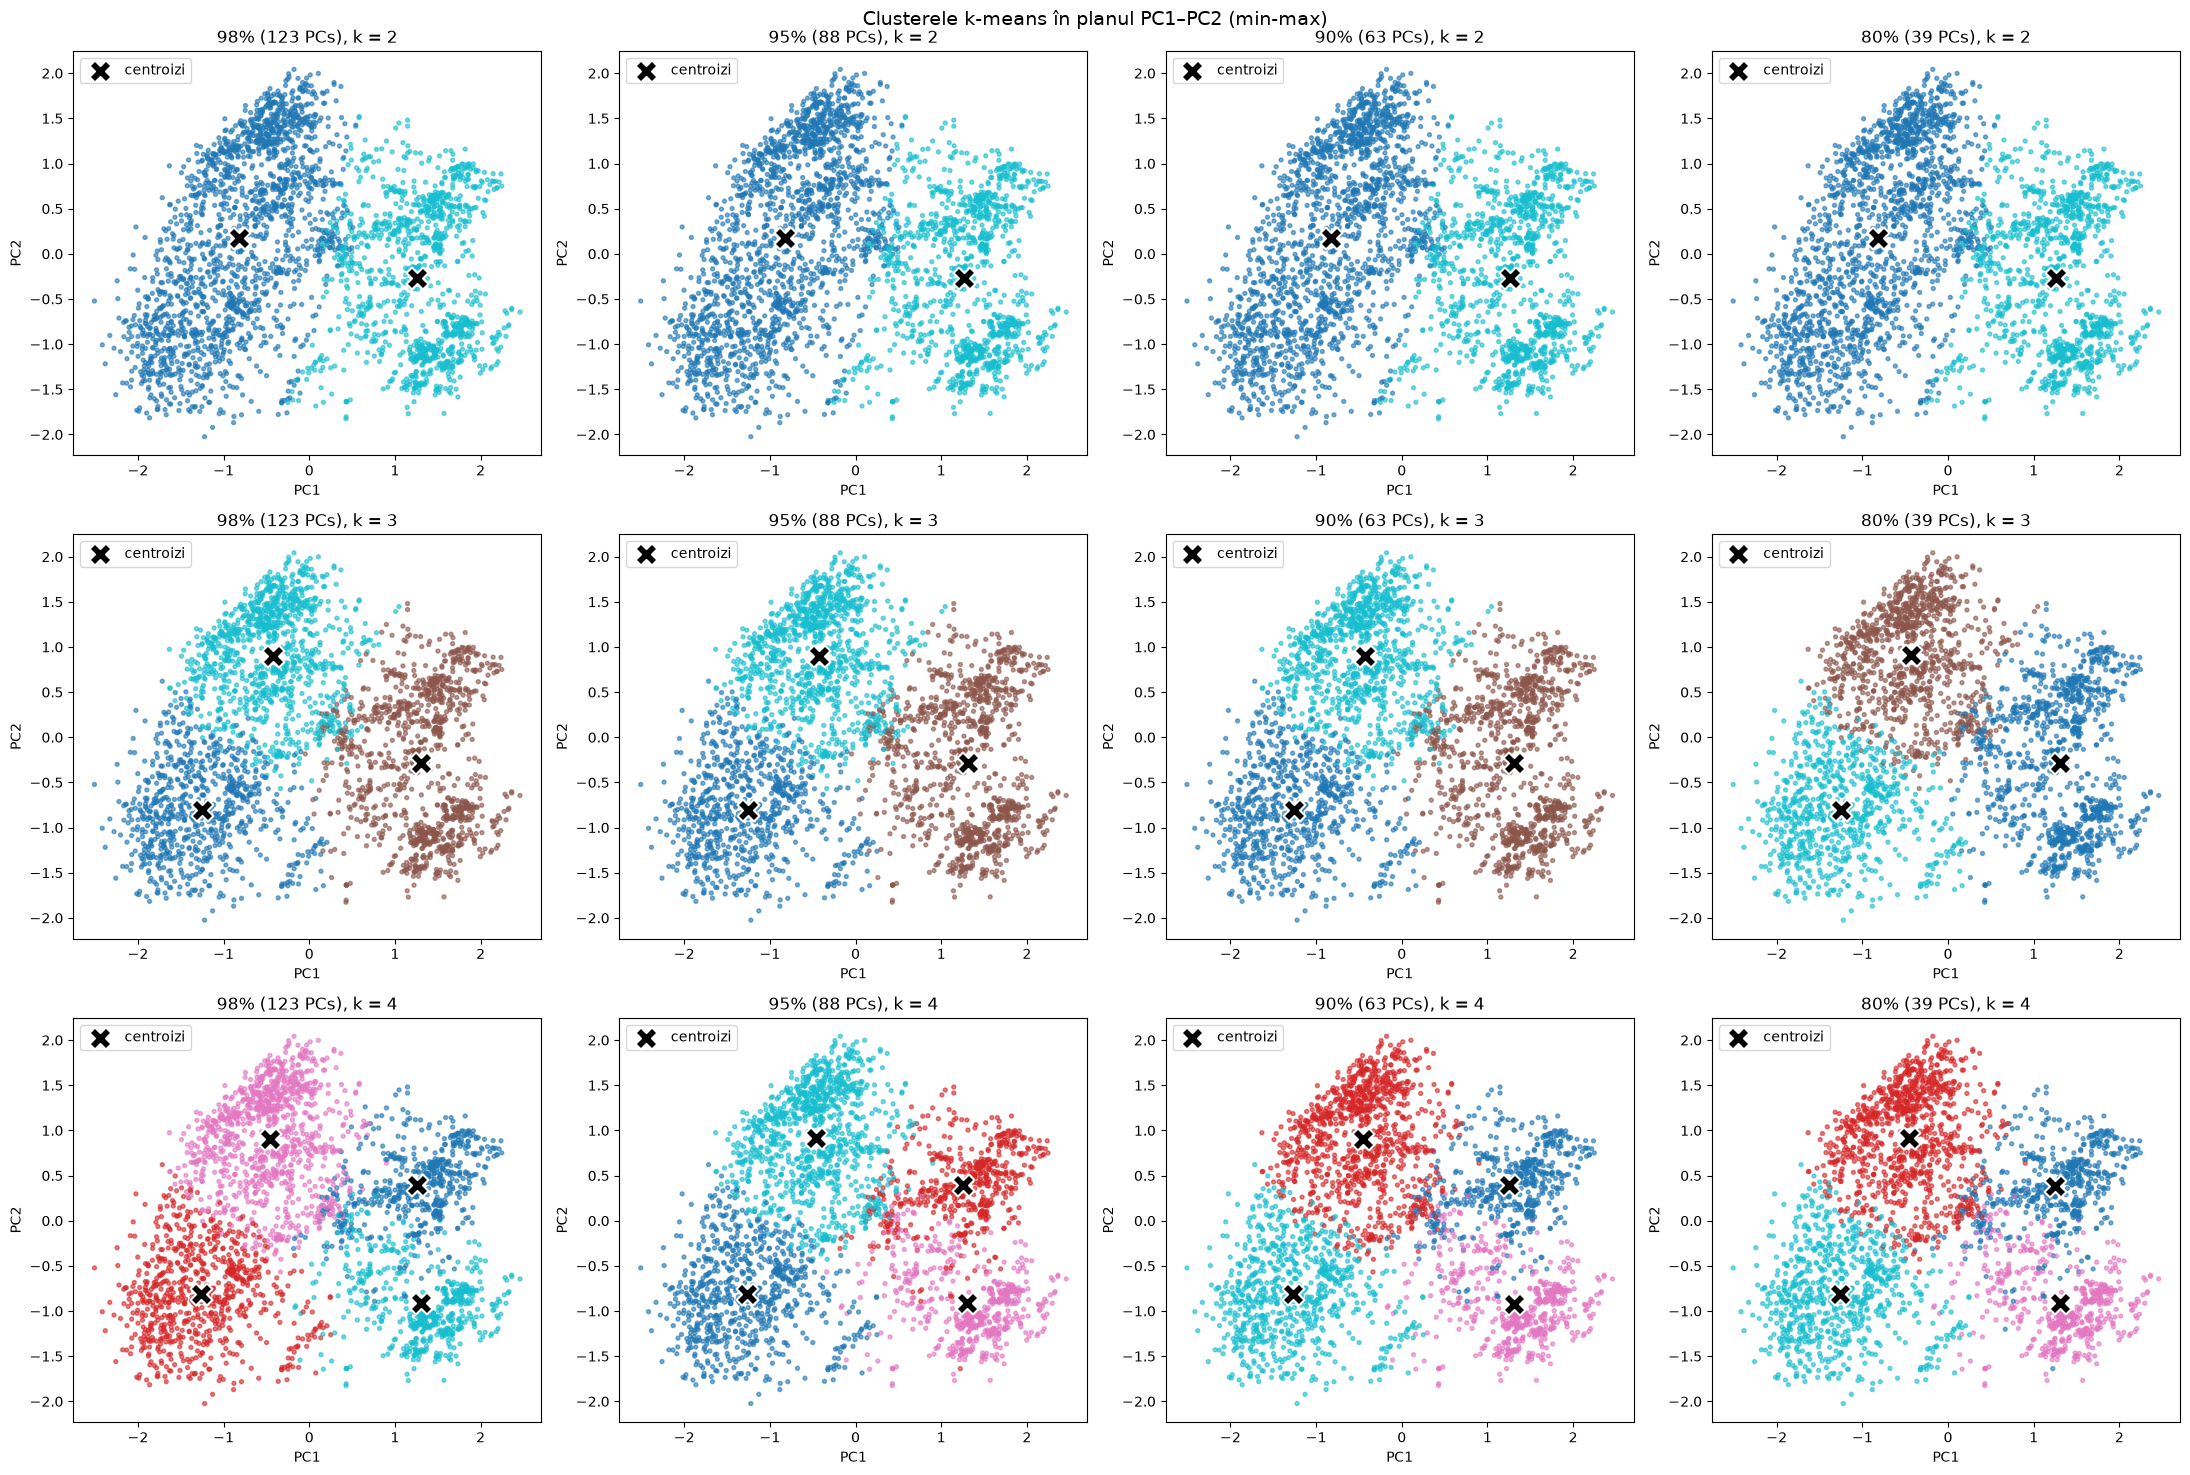

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(22, 15))
modele = {}                                   # salvăm modelele, le refolosim mai jos
for row, k in enumerate([2, 3, 4]):
    for col, t in enumerate(thresholds):
        Z = V["minmax"]["Z"][t]
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
        modele[(t, k)] = km
        ax = axes[row, col]
        ax.scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap="tab10", s=8, alpha=0.6)
        ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
                   c="black", marker="X", s=250, edgecolors="white", linewidths=1.5, label="centroizi")
        ax.set(title=f"{int(t*100)}% ({Z.shape[1]} PCs), k = {k}", xlabel="PC1", ylabel="PC2")
        ax.legend(loc="upper left")
plt.suptitle("Clusterele k-means în planul PC1–PC2 (min-max)", fontsize=14)
plt.tight_layout(); plt.show()

In [13]:
from sklearn.metrics import adjusted_rand_score

for k in [2, 3, 4]:
    ref = modele[(0.98, k)].labels_
    print(f"k = {k}:", {f"{int(t*100)}%": round(adjusted_rand_score(ref, modele[(t, k)].labels_), 3)
                        for t in thresholds})

k = 2: {'98%': 1.0, '95%': 0.995, '90%': 0.997, '80%': 0.997}
k = 3: {'98%': 1.0, '95%': 0.999, '90%': 0.999, '80%': 0.996}
k = 4: {'98%': 1.0, '95%': 0.995, '90%': 0.997, '80%': 0.99}


In [14]:
X = V["minmax"]["X"]
coloane_profil = {"Year Built": "an_constructie", "House Style_1Story": "un_etaj", "House Style_2Story": "doua_etaje",
                  "Garage Type_Attchd": "garaj_atasat", "Gr Liv Area": "suprafata", "Overall Qual": "calitate"}
for k in [2, 3, 4]:
    d = X[list(coloane_profil)].rename(columns=coloane_profil).copy()
    d["clasa_pret"] = y.values
    d["cluster"] = modele[(0.98, k)].labels_
    profil = d.groupby("cluster").mean()
    profil["an_constructie"] = d.groupby("cluster")["an_constructie"].median()
    profil["suprafata"] = d.groupby("cluster")["suprafata"].median()
    profil.insert(0, "case", d.groupby("cluster").size())
    print(f"k = {k}")
    display(profil.round(2))

k = 2


,case,an_constructie,un_etaj,doua_etaje,garaj_atasat,suprafata,calitate,clasa_pret
cluster,,,,,,,,
0,1774,1958.0,0.52,0.19,0.46,1252.0,5.36,1.63
1,1156,2003.0,0.48,0.47,0.79,1657.5,7.23,3.17


k = 3


,case,an_constructie,un_etaj,doua_etaje,garaj_atasat,suprafata,calitate,clasa_pret
cluster,,,,,,,,
0,790,1931.0,0.23,0.32,0.11,1315.5,5.21,1.26
1,1099,2004.0,0.48,0.47,0.80,1665.0,7.26,3.20
2,1041,1966.0,0.74,0.10,0.73,1226.0,5.54,1.95


k = 4


,case,an_constructie,un_etaj,doua_etaje,garaj_atasat,suprafata,calitate,clasa_pret
cluster,,,,,,,,
0,562,2005.0,0.97,0.00,0.94,1504.0,7.37,3.20
1,774,1930.0,0.22,0.32,0.11,1316.5,5.21,1.25
2,1023,1965.0,0.75,0.09,0.72,1212.0,5.50,1.91
3,571,2000.0,0.00,0.94,0.68,1874.0,7.11,3.20


**Interpretare**

Toate cele patru praguri dau aceleași clustere: centroizii sunt în aceleași poziții, iar ARI față de setul de 98% este între 0.99 și 1.0 (unde culorile diferă, clusterele sunt doar numerotate altfel). Ultimele componente au varianță foarte mică, deci aproape nu schimbă distanțele dintre case.

- **k = 2** împarte casele după PC1: case vechi (an median 1958, calitate 5.4) vs. case noi (2003, calitate 7.2, mai mari).
- **k = 3** împarte casele vechi în două: cele mai vechi (în jur de 1931, fără garaj atașat, cele mai ieftine) și casele cu un etaj din anii '60 (74% cu un etaj, garaj atașat).
- **k = 4** împarte și casele noi: cu un etaj (97%) vs. cu două etaje (94%). Sunt cele două grupuri dense din dreapta. Au aceeași clasă medie de preț (3.2), deci diferă prin formă, nu prin preț.

## 3. Experiment: k-means fără coloanele one-hot

În partea 1 s-a văzut că primele componente sunt dominate de coloane one-hot (tipul fundației, exteriorul, stilul casei), nu de suprafețe sau calitate. Vreau să văd cum se schimbă clusterele dacă păstrez doar coloanele numerice și ordinale (55 din 250) și elimin coloanele one-hot. Restul pașilor rămân la fel: scalare, PCA, apoi k-means pentru k = 2…6.

In [15]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from lab3_utils import get_data

X_full, _ = get_data(path="../data/AmesHousing.csv", impute=True, ordinal=True)
onehot = [c for c in X_full.columns if "_" in c and X_full[c].nunique() <= 2]
X_num = X_full.drop(columns=onehot)
print("Coloane totale:", X_full.shape[1], "| one-hot:", len(onehot), "| rămase:", X_num.shape[1])

rows = []
for nume, scaler in [("minmax", MinMaxScaler()), ("standard", StandardScaler())]:
    X_s = scaler.fit_transform(X_num)
    for t in [0.98, 0.80]:
        Z = PCA(n_components=t, svd_solver="full", random_state=SEED).fit_transform(X_s)
        for k in range(2, 7):
            labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
            rows.append({"date": "fără one-hot", "variant": nume, "threshold": t, "components": Z.shape[1], "k": k,
                         "silhouette": silhouette_score(Z, labels), "ari_price": adjusted_rand_score(y, labels)})
fara_onehot = pd.DataFrame(rows)

# Comparație cu toate coloanele (din tabelul grid)
cu_onehot = grid[grid["variant"].isin(["minmax", "standard"]) & grid["threshold"].isin([0.98, 0.80]) & (grid["k"] <= 6)].copy()
cu_onehot["date"] = "toate coloanele"
comparatie = pd.concat([cu_onehot, fara_onehot])
comparatie.to_csv("kmeans_fara_onehot.csv", index=False)

display(comparatie.pivot_table(index=["variant", "threshold", "k"], columns="date",
                               values=["silhouette", "ari_price"]).round(3))

Coloane totale: 250 | one-hot: 195 | rămase: 55


ari_price                   silhouette                
date                 fără one-hot toate coloanele fără one-hot toate coloanele
variant  threshold k                                                          
minmax   0.80      2        0.203           0.149        0.203           0.128
                   3        0.224           0.156        0.181           0.126
                   4        0.203           0.142        0.164           0.120
                   5        0.164           0.114        0.159           0.121
                   6        0.151           0.113        0.154           0.124
         0.98      2        0.203           0.149        0.172           0.103
                   3        0.222           0.156        0.154           0.103
                   4        0.194           0.142        0.114           0.090
                   5        0.163           0.111        0.127           0.093
                   6        0.152           0.112        0.121           0.097
standard 0.80      2        0.228           0.192        0.176           0.068
                   3        0.239           0.180        0.173           0.057
                   4        0.269           0.171        0.123           0.048
                   5        0.227           0.175        0.110           0.036
                   6        0.212           0.176        0.140           0.040
         0.98      2        0.229           0.189        0.142           0.052
                   3        0.255           0.179        0.130           0.039
                   4        0.269           0.172        0.090           0.028
                   5        0.267           0.169        0.082           0.014
                   6        0.183           0.174        0.098           0.016

**Interpretare**

Fără coloanele one-hot, scorul silhouette crește în toate variantele (min-max, 80%, k = 2: de la 0.128 la 0.203), iar clusterele seamănă mai mult cu clasele de preț (ARI de la ~0.15 la ~0.20–0.27). Standardizarea câștigă cel mai mult (0.068 → 0.176), ceea ce confirmă că problema ei erau coloanele one-hot rare. Alegerea features-urilor contează mai mult decât scalarea sau pragul PCA.

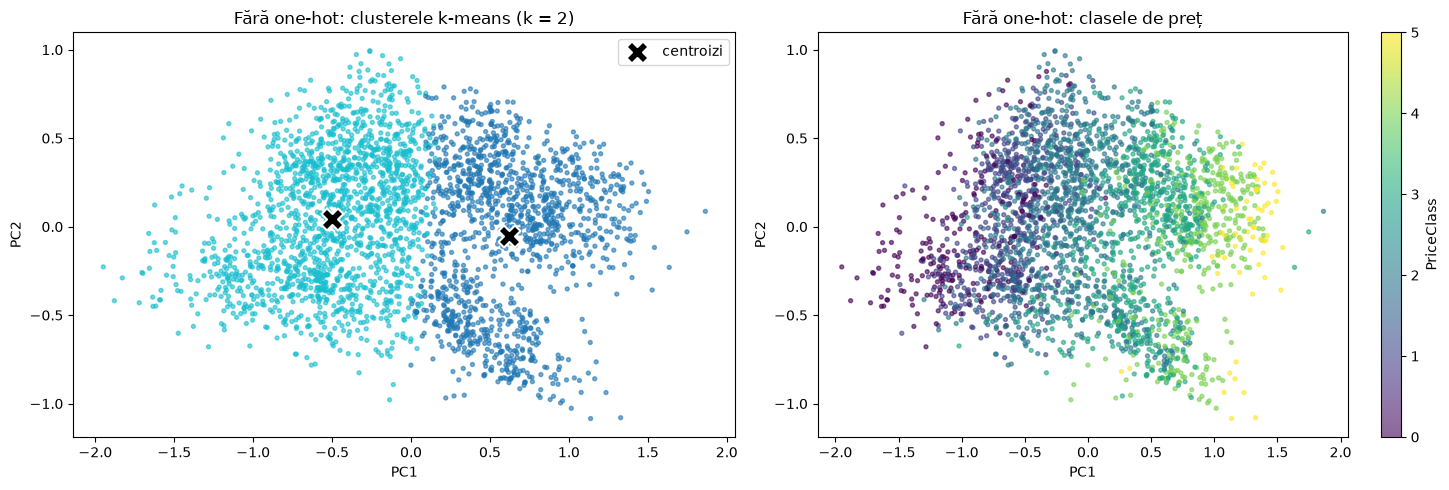

PC1 explică 25.6 % din varianță | corelația PC1 cu clasa de preț: 0.849


,toate coloanele,fără one-hot
<100k,0.4,0.4
100–130k,0.8,0.2
130–180k,25.0,27.2
180–250k,71.1,84.0
250–400k,86.1,97.5
≥400k,96.9,100.0


In [16]:
pca_num = PCA(n_components=0.98, svd_solver="full", random_state=SEED)
Z_num = pca_num.fit_transform(MinMaxScaler().fit_transform(X_num))
km_num = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(Z_num)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(Z_num[:, 0], Z_num[:, 1], c=km_num.labels_, cmap="tab10", s=8, alpha=0.6)
axes[0].scatter(km_num.cluster_centers_[:, 0], km_num.cluster_centers_[:, 1], c="black", marker="X", s=250,
                edgecolors="white", linewidths=1.5, label="centroizi")
axes[0].set(title="Fără one-hot: clusterele k-means (k = 2)", xlabel="PC1", ylabel="PC2")
axes[0].legend()
sc = axes[1].scatter(Z_num[:, 0], Z_num[:, 1], c=y, cmap="viridis", s=8, alpha=0.6)
axes[1].set(title="Fără one-hot: clasele de preț", xlabel="PC1", ylabel="PC2")
fig.colorbar(sc, ax=axes[1], label="PriceClass")
plt.tight_layout(); plt.show()

print("PC1 explică", round(pca_num.explained_variance_ratio_[0] * 100, 1), "% din varianță",
      "| corelația PC1 cu clasa de preț:", round(np.corrcoef(Z_num[:, 0], y)[0, 1], 3))

def procent_in_clusterul_scump(labels):
    # clusterul "scump" = cel cu clasa de preț medie mai mare
    scump = pd.Series(y.values).groupby(labels).mean().idxmax()
    return pd.Series(labels == scump).groupby(y.values).mean() * 100

tabel = pd.DataFrame({"toate coloanele": procent_in_clusterul_scump(modele[(0.98, 2)].labels_),
                      "fără one-hot": procent_in_clusterul_scump(km_num.labels_)}).round(1)
tabel.index = ["<100k", "100–130k", "130–180k", "180–250k", "250–400k", "≥400k"]
display(tabel)

Fără one-hot, PC1 explică 25.6% din varianță (față de 13.2%) și e mai corelat cu clasa de preț (0.85 față de 0.75). Cu k = 2, clusterele separă mai curat casele ieftine de cele scumpe: 97.5% din casele de 250–400k și toate cele ≥400k ajung în același cluster (față de 86% și 97% cu toate coloanele), iar casele sub 130k ajung aproape toate în celălalt.

### 3.1 Stabilitatea clusterelor

K-means pornește din centroizi aleși aleator, deci rezultatul poate depinde de seed. Rulez k-means cu 5 seed-uri diferite și compar clusterele între ele cu ARI (1 = identice). Clusterele sunt de încredere doar dacă ies la fel indiferent de seed.

In [17]:
seeds = [0, 1, 7, 42, 123]
date_test = {"toate coloanele": V["minmax"]["Z"][0.98],
             "fără one-hot": PCA(n_components=0.98, svd_solver="full", random_state=SEED)
                                .fit_transform(MinMaxScaler().fit_transform(X_num))}

rows = []
for nume, Z in date_test.items():
    for k in [2, 3, 4]:
        etichete = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(Z) for s in seeds]
        ari = [adjusted_rand_score(etichete[i], etichete[j])
               for i in range(len(seeds)) for j in range(i + 1, len(seeds))]
        rows.append({"date": nume, "k": k, "ARI minim": min(ari), "ARI mediu": np.mean(ari)})
display(pd.DataFrame(rows).round(3))

,date,k,ARI minim,ARI mediu
0,toate coloanele,2,0.997,0.999
1,toate coloanele,3,0.992,0.996
2,toate coloanele,4,0.771,0.907
3,fără one-hot,2,1.000,1.000
4,fără one-hot,3,0.686,0.812
5,fără one-hot,4,0.672,0.801


**Interpretare**

Pentru k = 2 clusterele sunt stabile în ambele cazuri (ARI ≥ 0.997; fără one-hot chiar identice). Cu toate coloanele, k = 3 este încă stabil (0.992), dar k = 4 nu (0.771). Fără one-hot, deja k = 3 devine instabil (0.686): nu există un al treilea grup natural, iar k-means îl formează diferit la fiecare rulare. Cu toate coloanele, al treilea cluster e stabil pentru că este susținut de coloane one-hot (stilul casei, tipul garajului), care lipsesc în al doilea caz. Alegerea cea mai robustă este k = 2.

## Concluzie — Partea 2

- **Casele nu formează grupuri bine separate.** Scorul silhouette rămâne mic în toate variantele (maxim ~0.13 cu toate coloanele, ~0.20 fără one-hot).
- **Cel mai bun număr de clustere este k = 2** (silhouette, Calinski-Harabasz, doar 7% valori negative, stabil la orice seed): case vechi vs. case noi, de-a lungul lui PC1.
- **k = 3 și k = 4 au sens, dar sunt mai slabe:** k = 3 separă casele cele mai vechi de cele cu un etaj din anii '60, iar k = 4 împarte casele noi după numărul de etaje. La k = 4 clusterele depind deja de seed.
- **Pragul PCA nu contează:** 98%, 95%, 90% și 80% dau practic aceleași clustere (ARI ≥ 0.99).
- **Scalarea contează:** min-max dă un silhouette de ~2× mai mare decât standardizarea și clustere parțial diferite (ARI 0.80). **Logaritmarea aproape nu contează** (ARI 0.97).
- **Alegerea features-urilor contează cel mai mult:** fără coloanele one-hot, clusterele sunt mai bine separate și urmează mai clar prețul.

- **Normalizarea L2 pe rânduri** dă un silhouette mare (~0.6), dar clusterele sunt determinate doar de `Lot Area` și nu au legătură cu prețul: un scor bun nu garantează clustere cu sens.